In [51]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [48]:
data_path = "C:\\AI Equipment Failure Prediction\\data\\20_cmapss_fd001_sample.csv"

In [49]:
import matplotlib.pyplot as plt

# Windows 한글 글꼴 설정
plt.rcParams['font.family'] = 'Malgun Gothic'

# 음수 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

In [50]:
df = pd.read_csv(data_path)

In [20]:
df = df.rename(columns={
    'unit_nr': 'unit_nr_엔진번호',
    'time_cycles': 'time_cycles_운전주기',
    'setting_1': 'setting_1_고도',
    'setting_2': 'setting_2_마하수',
    'setting_3': 'setting_3_스로틀',
    's_1': 's_1_팬입구온도',
    's_2': 's_2_저압압축기출구온도',
    's_3': 's_3_고압압축기출구온도',
    's_4': 's_4_저압터빈출구온도',
    's_5': 's_5_팬입구압력',
    's_6': 's_6_바이패스통로압력',
    's_7': 's_7_고압압축기출구압력',
    's_8': 's_8_팬회전속도',
    's_9': 's_9_엔진코어회전속도',
    's_10': 's_10_엔진내부압력비',
    's_11': 's_11_고압압축기출구정압',
    's_12': 's_12_연료흐름압력비',
    's_13': 's_13_보정팬회전속도',
    's_14': 's_14_보정엔진코어회전속도',
    's_15': 's_15_바이패스공기비율',
    's_16': 's_16_연료공기비율',
    's_17': 's_17_냉각공기관련값',
    's_18': 's_18_목표팬회전속도',
    's_19': 's_19_보정목표팬회전속도',
    's_20': 's_20_고압터빈냉각공기흐름',
    's_21': 's_21_저압터빈냉각공기흐름'
})

In [40]:
df.head()

,unit_nr,time_cycles,setting_1,setting_2,setting_3,s_1,s_2,s_3,s_4,s_5,...,s_12,s_13,s_14,s_15,s_16,s_17,s_18,s_19,s_20,s_21
0,1,1,0.0010,-0.0000,100.0,518.67,641.17,1589.63,1399.16,14.62,...,520.73,2387.98,8132.98,8.344,0.03,391,2388,100.0,38.85,23.2468
1,1,2,0.0006,-0.0003,100.0,518.67,640.66,1589.52,1399.28,14.62,...,521.11,2387.97,8126.66,8.385,0.03,394,2388,100.0,38.89,23.2419
2,1,3,0.0016,-0.0004,100.0,518.67,641.08,1579.31,1394.97,14.62,...,520.15,2387.97,8124.71,8.436,0.03,392,2388,100.0,38.74,23.3084
3,1,4,-0.0008,-0.0002,100.0,518.67,641.18,1588.34,1404.10,14.62,...,520.76,2387.95,8115.96,8.430,0.03,393,2388,100.0,38.88,23.3398
4,1,5,0.0007,-0.0002,100.0,518.67,641.13,1589.93,1400.33,14.62,...,520.86,2387.91,8127.75,8.417,0.03,393,2388,100.0,38.84,23.2466


In [8]:
df.std().round(2).sort_values(ascending=False)

time_cycles_운전주기    72.26
s_14_보정엔진코어회전속도     12.79
s_9_엔진코어회전속도        10.23
s_4_저압터빈출구온도         6.39
s_3_고압압축기출구온도        4.57
s_7_고압압축기출구압력        2.37
s_12_연료흐름압력비         2.12
s_17_냉각공기관련값         1.45
unit_nr_엔진번호         1.44
s_2_저압압축기출구온도        0.50
s_11_고압압축기출구정압       0.31
s_20_고압터빈냉각공기흐름      0.27
s_21_저압터빈냉각공기흐름      0.15
s_8_팬회전속도            0.10
s_13_보정팬회전속도         0.08
s_15_바이패스공기비율        0.08
setting_1_고도         0.00
s_1_팬입구온도            0.00
s_5_팬입구압력            0.00
setting_2_마하수        0.00
setting_3_스로틀        0.00
s_6_바이패스통로압력         0.00
s_10_엔진내부압력비         0.00
s_16_연료공기비율          0.00
s_19_보정목표팬회전속도       0.00
s_18_목표팬회전속도         0.00
dtype: float64

In [ ]:
e1=df[df['unit_nr_엔진번호'] == 1].sort_values('time_cycles_운전주기')
e1.head()


,unit_nr_엔진번호,time_cycles_운전주기,setting_1_고도,setting_2_마하수,setting_3_스로틀,s_1_팬입구온도,s_2_저압압축기출구온도,s_3_고압압축기출구온도,s_4_저압터빈출구온도,s_5_팬입구압력,...,s_12_연료흐름압력비,s_13_보정팬회전속도,s_14_보정엔진코어회전속도,s_15_바이패스공기비율,s_16_연료공기비율,s_17_냉각공기관련값,s_18_목표팬회전속도,s_19_보정목표팬회전속도,s_20_고압터빈냉각공기흐름,s_21_저압터빈냉각공기흐름
0,1,1,0.0010,-0.0000,100.0,518.67,641.17,1589.63,1399.16,14.62,...,520.73,2387.98,8132.98,8.344,0.03,391,2388,100.0,38.85,23.2468
1,1,2,0.0006,-0.0003,100.0,518.67,640.66,1589.52,1399.28,14.62,...,521.11,2387.97,8126.66,8.385,0.03,394,2388,100.0,38.89,23.2419
2,1,3,0.0016,-0.0004,100.0,518.67,641.08,1579.31,1394.97,14.62,...,520.15,2387.97,8124.71,8.436,0.03,392,2388,100.0,38.74,23.3084
3,1,4,-0.0008,-0.0002,100.0,518.67,641.18,1588.34,1404.10,14.62,...,520.76,2387.95,8115.96,8.430,0.03,393,2388,100.0,38.88,23.3398
4,1,5,0.0007,-0.0002,100.0,518.67,641.13,1589.93,1400.33,14.62,...,520.86,2387.91,8127.75,8.417,0.03,393,2388,100.0,38.84,23.2466


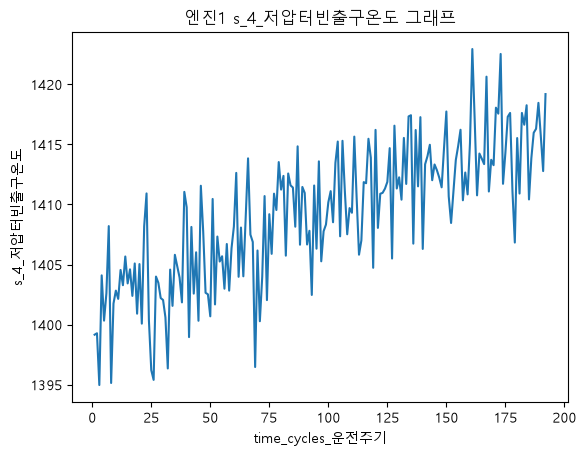

In [10]:
plt.plot(e1['time_cycles_운전주기'], e1['s_4_저압터빈출구온도'])

plt.xlabel('time_cycles_운전주기')
plt.ylabel('s_4_저압터빈출구온도')
plt.title('엔진1 s_4_저압터빈출구온도 그래프')



plt.show()

표준편차가 0에 가까운 센서(s_1, s_5, s_6, s_10, s_16, s_18, s_19 등)는 정보가 거의 없으므로 분석에서 제외합니다. 변하는 센서(s_2, s_3, s_4, s_7, s_11, s_12 등)에 집중하세요.

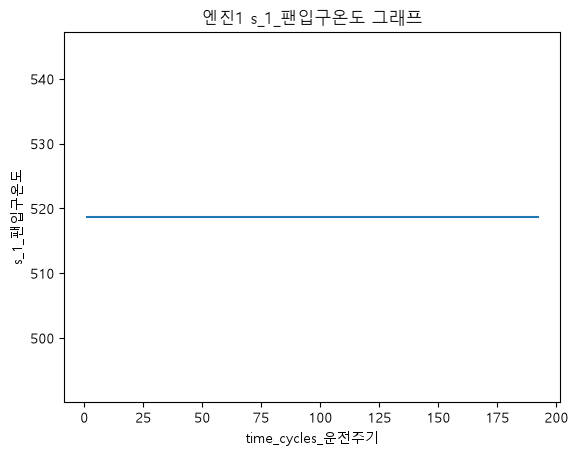

In [11]:
plt.plot(e1['time_cycles_운전주기'], e1['s_1_팬입구온도'])

plt.xlabel('time_cycles_운전주기')
plt.ylabel('s_1_팬입구온도')
plt.title('엔진1 s_1_팬입구온도 그래프')



plt.show()

In [12]:
e1.columns

Index(['unit_nr_엔진번호', 'time_cycles_운전주기', 'setting_1_고도', 'setting_2_마하수',
       'setting_3_스로틀', 's_1_팬입구온도', 's_2_저압압축기출구온도', 's_3_고압압축기출구온도',
       's_4_저압터빈출구온도', 's_5_팬입구압력', 's_6_바이패스통로압력', 's_7_고압압축기출구압력',
       's_8_팬회전속도', 's_9_엔진코어회전속도', 's_10_엔진내부압력비', 's_11_고압압축기출구정압',
       's_12_연료흐름압력비', 's_13_보정팬회전속도', 's_14_보정엔진코어회전속도', 's_15_바이패스공기비율',
       's_16_연료공기비율', 's_17_냉각공기관련값', 's_18_목표팬회전속도', 's_19_보정목표팬회전속도',
       's_20_고압터빈냉각공기흐름', 's_21_저압터빈냉각공기흐름'],
      dtype='str')

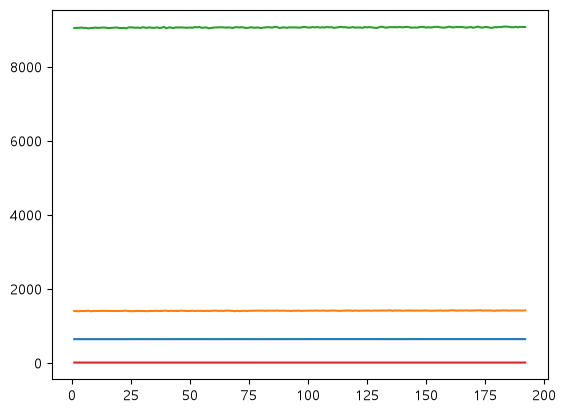

In [13]:
plt.plot(e1['time_cycles_운전주기'], e1['s_2_저압압축기출구온도'])
plt.plot(e1['time_cycles_운전주기'], e1['s_4_저압터빈출구온도'])
plt.plot(e1['time_cycles_운전주기'], e1['s_9_엔진코어회전속도'])
plt.plot(e1['time_cycles_운전주기'], e1['s_15_바이패스공기비율'])



In [14]:
#실습1

In [15]:
df.shape

(1116, 26)

In [16]:
df.columns.to_list()

['unit_nr_엔진번호',
 'time_cycles_운전주기',
 'setting_1_고도',
 'setting_2_마하수',
 'setting_3_스로틀',
 's_1_팬입구온도',
 's_2_저압압축기출구온도',
 's_3_고압압축기출구온도',
 's_4_저압터빈출구온도',
 's_5_팬입구압력',
 's_6_바이패스통로압력',
 's_7_고압압축기출구압력',
 's_8_팬회전속도',
 's_9_엔진코어회전속도',
 's_10_엔진내부압력비',
 's_11_고압압축기출구정압',
 's_12_연료흐름압력비',
 's_13_보정팬회전속도',
 's_14_보정엔진코어회전속도',
 's_15_바이패스공기비율',
 's_16_연료공기비율',
 's_17_냉각공기관련값',
 's_18_목표팬회전속도',
 's_19_보정목표팬회전속도',
 's_20_고압터빈냉각공기흐름',
 's_21_저압터빈냉각공기흐름']

In [17]:
df.head()

,unit_nr_엔진번호,time_cycles_운전주기,setting_1_고도,setting_2_마하수,setting_3_스로틀,s_1_팬입구온도,s_2_저압압축기출구온도,s_3_고압압축기출구온도,s_4_저압터빈출구온도,s_5_팬입구압력,...,s_12_연료흐름압력비,s_13_보정팬회전속도,s_14_보정엔진코어회전속도,s_15_바이패스공기비율,s_16_연료공기비율,s_17_냉각공기관련값,s_18_목표팬회전속도,s_19_보정목표팬회전속도,s_20_고압터빈냉각공기흐름,s_21_저압터빈냉각공기흐름
0,1,1,0.0010,-0.0000,100.0,518.67,641.17,1589.63,1399.16,14.62,...,520.73,2387.98,8132.98,8.344,0.03,391,2388,100.0,38.85,23.2468
1,1,2,0.0006,-0.0003,100.0,518.67,640.66,1589.52,1399.28,14.62,...,521.11,2387.97,8126.66,8.385,0.03,394,2388,100.0,38.89,23.2419
2,1,3,0.0016,-0.0004,100.0,518.67,641.08,1579.31,1394.97,14.62,...,520.15,2387.97,8124.71,8.436,0.03,392,2388,100.0,38.74,23.3084
3,1,4,-0.0008,-0.0002,100.0,518.67,641.18,1588.34,1404.10,14.62,...,520.76,2387.95,8115.96,8.430,0.03,393,2388,100.0,38.88,23.3398
4,1,5,0.0007,-0.0002,100.0,518.67,641.13,1589.93,1400.33,14.62,...,520.86,2387.91,8127.75,8.417,0.03,393,2388,100.0,38.84,23.2466


In [18]:
#실습2 

In [19]:
df['unit_nr_엔진번호'].value_counts().sort_index()

unit_nr_엔진번호
1    192
2    287
3    179
4    189
5    269
Name: count, dtype: int64

In [20]:
#실습3

In [55]:
e2 = df[df['unit_nr'] == 2]
# e2.head()

In [22]:
e2_sample = e2[['s_2_저압압축기출구온도', 's_11_고압압축기출구정압', 's_12_연료흐름압력비']] 
e2_sample.describe()

,s_2_저압압축기출구온도,s_11_고압압축기출구정압,s_12_연료흐름압력비
count,287.000000,287.000000,287.000000
mean,641.752997,47.690244,517.430105
std,0.486257,0.315732,2.146613
min,640.460000,46.970000,512.860000
25%,641.390000,47.420000,515.655000
50%,641.700000,47.680000,517.230000
75%,642.140000,47.940000,519.155000
max,642.870000,48.440000,521.960000


In [23]:
#4

표준편차가 0에 가까운 센서(s_1, s_5, s_6, s_10, s_16, s_18, s_19 등)는 정보가 거의 없으므로 분석에서 제외합니다. 
변하는 센서(s_2, s_3, s_4, s_7, s_11, s_12 등)에 집중하세요.

In [24]:
df.std().round(2).sort_values()

setting_2_마하수        0.00
setting_1_고도         0.00
s_1_팬입구온도            0.00
setting_3_스로틀        0.00
s_6_바이패스통로압력         0.00
s_10_엔진내부압력비         0.00
s_5_팬입구압력            0.00
s_18_목표팬회전속도         0.00
s_19_보정목표팬회전속도       0.00
s_16_연료공기비율          0.00
s_13_보정팬회전속도         0.08
s_15_바이패스공기비율        0.08
s_8_팬회전속도            0.10
s_21_저압터빈냉각공기흐름      0.15
s_20_고압터빈냉각공기흐름      0.27
s_11_고압압축기출구정압       0.31
s_2_저압압축기출구온도        0.50
unit_nr_엔진번호         1.44
s_17_냉각공기관련값         1.45
s_12_연료흐름압력비         2.12
s_7_고압압축기출구압력        2.37
s_3_고압압축기출구온도        4.57
s_4_저압터빈출구온도         6.39
s_9_엔진코어회전속도        10.23
s_14_보정엔진코어회전속도     12.79
time_cycles_운전주기    72.26
dtype: float64

In [25]:
#실습5

In [26]:
e2 = df[df['unit_nr_엔진번호']==2].sort_values(by='time_cycles_운전주기')
#e2.head()


In [27]:
print(e2['s_11_고압압축기출구정압'].head(1), 
      e2['s_11_고압압축기출구정압'].tail(1))

192    47.3
Name: s_11_고압압축기출구정압, dtype: float64 478    48.18
Name: s_11_고압압축기출구정압, dtype: float64


In [28]:
print(e2['s_11_고압압축기출구정압'].iloc[0])
print(e2['s_11_고압압축기출구정압'].iloc[-1])

47.3
48.18


In [29]:
print(e2['s_7_고압압축기출구압력'].iloc[0])
print(e2['s_7_고압압축기출구압력'].iloc[-1])

553.84
546.17


In [30]:
# 실습6

In [31]:

#df.columns.tolist()

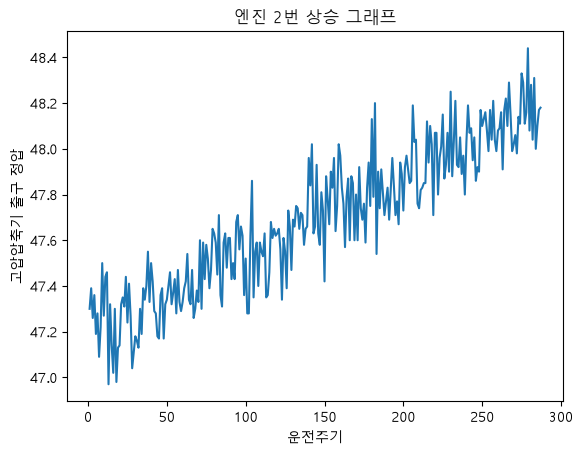

In [32]:
plt.plot(e2['time_cycles_운전주기'], e2['s_11_고압압축기출구정압']) #상승 

plt.title('엔진 2번 상승 그래프')
plt.xlabel('운전주기')
plt.ylabel('고압압축기 출구 정압')

plt.show()

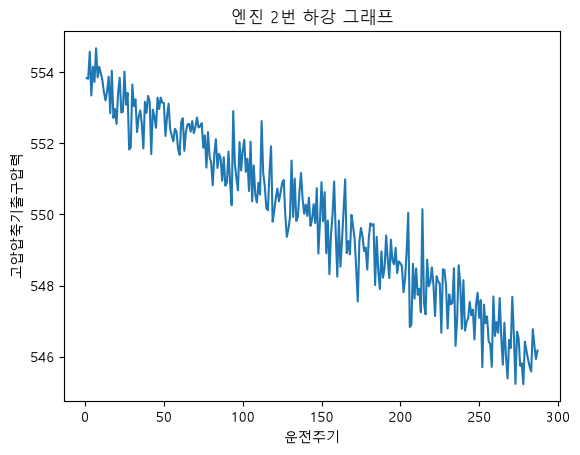

In [33]:
plt.plot(e2['time_cycles_운전주기'], e2['s_7_고압압축기출구압력'])

plt.title('엔진 2번 하강 그래프')
plt.xlabel('운전주기')
plt.ylabel('고압압축기출구압력')

plt.show()

In [34]:
#실습 6 
#s5 s12

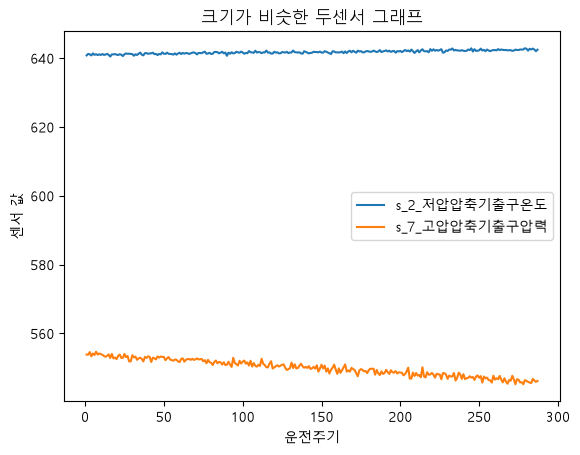

In [35]:
plt.plot(e2['time_cycles_운전주기'], e2['s_2_저압압축기출구온도'])
plt.plot(e2['time_cycles_운전주기'], e2['s_7_고압압축기출구압력'])

plt.legend(['s_2_저압압축기출구온도', 's_7_고압압축기출구압력'])

plt.title('크기가 비슷한 두센서 그래프')
plt.xlabel('운전주기')
plt.ylabel('센서 값')
plt.show()

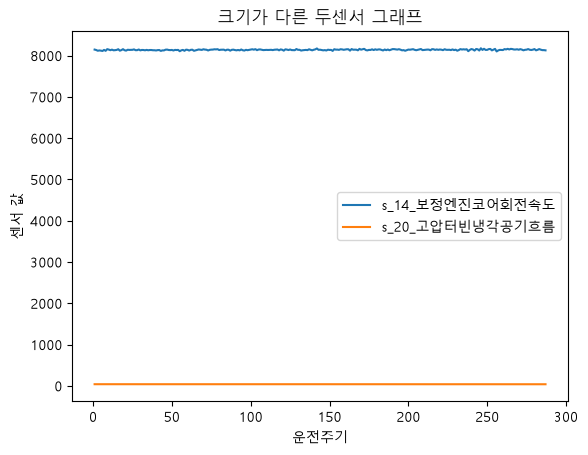

In [36]:
plt.plot(e2['time_cycles_운전주기'], e2['s_14_보정엔진코어회전속도'])
plt.plot(e2['time_cycles_운전주기'], e2['s_20_고압터빈냉각공기흐름'])

plt.legend(['s_14_보정엔진코어회전속도', 's_20_고압터빈냉각공기흐름'])

plt.title('크기가 다른 두센서 그래프')
plt.xlabel('운전주기')
plt.ylabel('센서 값')
plt.show()

In [37]:
#'s_14_보정엔진코어회전속도' 
#'s_20_고압터빈냉각공기흐름'

In [38]:
e2['s_14_보정엔진코어회전속도'].describe()

count     287.000000
mean     8138.262334
std        11.930483
min      8099.120000
25%      8130.815000
50%      8138.290000
75%      8145.940000
max      8176.360000
Name: s_14_보정엔진코어회전속도, dtype: float64

In [39]:
df.columns.to_list()

['unit_nr_엔진번호',
 'time_cycles_운전주기',
 'setting_1_고도',
 'setting_2_마하수',
 'setting_3_스로틀',
 's_1_팬입구온도',
 's_2_저압압축기출구온도',
 's_3_고압압축기출구온도',
 's_4_저압터빈출구온도',
 's_5_팬입구압력',
 's_6_바이패스통로압력',
 's_7_고압압축기출구압력',
 's_8_팬회전속도',
 's_9_엔진코어회전속도',
 's_10_엔진내부압력비',
 's_11_고압압축기출구정압',
 's_12_연료흐름압력비',
 's_13_보정팬회전속도',
 's_14_보정엔진코어회전속도',
 's_15_바이패스공기비율',
 's_16_연료공기비율',
 's_17_냉각공기관련값',
 's_18_목표팬회전속도',
 's_19_보정목표팬회전속도',
 's_20_고압터빈냉각공기흐름',
 's_21_저압터빈냉각공기흐름']

In [40]:
target = 2

# 2번 엔진을 선택하고 운전주기 순으로 정렬
g = df[df['unit_nr_엔진번호'] == target].sort_values('time_cycles_운전주기')

print(f'크기: {df.shape[0]}행 {df.shape[1]}열, 엔진 {df["unit_nr_엔진번호"].nunique()}대')

miss = '없음' if df.isna().sum().sum() == 0 else '있음'
print(f'엔진 {target} 회차 수: {len(g)}, 결측: {miss}')

# 첫 번째와 마지막 센서값 비교
for c in ['s_11_고압압축기출구정압',
          's_7_고압압축기출구압력',
          's_12_연료흐름압력비']:

    a, b = g[c].iloc[0], g[c].iloc[-1]
    print(f'  {c}: {a} -> {b} ({"상승" if b > a else "하강" if b < a else "동일"})')

크기: 1116행 26열, 엔진 5대
엔진 2 회차 수: 287, 결측: 없음
  s_11_고압압축기출구정압: 47.3 -> 48.18 (상승)
  s_7_고압압축기출구압력: 553.84 -> 546.17 (하강)
  s_12_연료흐름압력비: 520.52 -> 513.55 (하강)


# 오후 강의

In [114]:
data = "C:\\AI Equipment Failure Prediction\\data\\20_engine01_timestamp_sample.csv"

In [115]:
df = pd.read_csv(data)

In [116]:
df.head()

,timestamp,temp_out,temp_core,pressure,vibration,flow
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  182 non-null    str    
 1   temp_out   182 non-null    float64
 2   temp_core  182 non-null    float64
 3   pressure   180 non-null    float64
 4   vibration  179 non-null    float64
 5   flow       182 non-null    float64
dtypes: float64(5), str(1)
memory usage: 12.0 KB


In [ ]:
df['timestamp']

In [50]:
df['timestamp']=pd.to_datetime(df['timestamp'])

In [51]:
df['timestamp'].dtype

dtype('<M8[us]')

In [52]:
df['timestamp']

0     2024-03-01 00:00:00
1     2024-03-01 01:00:00
2     2024-03-01 02:00:00
3     2024-03-01 03:00:00
4     2024-03-01 04:00:00
              ...        
177   2024-03-08 19:00:00
178   2024-03-08 20:00:00
179   2024-03-08 21:00:00
180   2024-03-08 22:00:00
181   2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: datetime64[us]

In [53]:
df[df['timestamp'] == '2024-03-07']

,timestamp,temp_out,temp_core,pressure,vibration,flow
134,2024-03-07,641.9,1413.33,548.37,47.99,8.611


In [62]:
df['timestamp'].dt.second

0      0
1      0
2      0
3      0
4      0
      ..
177    0
178    0
179    0
180    0
181    0
Name: timestamp, Length: 182, dtype: int32

In [63]:
dates = ['2023-01-01', '2023-02-30', 'invalid_date', '2023-03-15', None]

In [73]:
date_series = pd.to_datetime(dates,errors='coerce')

In [68]:
pd.to_datetime(df['timestamp'], format='%Y-%m-%d')

0     2024-03-01 00:00:00
1     2024-03-01 01:00:00
2     2024-03-01 02:00:00
3     2024-03-01 03:00:00
4     2024-03-01 04:00:00
              ...        
177   2024-03-08 19:00:00
178   2024-03-08 20:00:00
179   2024-03-08 21:00:00
180   2024-03-08 22:00:00
181   2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: datetime64[us]

In [75]:
date_series.isna().sum()

np.int64(3)

In [79]:
date_series.dropna()

DatetimeIndex(['2023-01-01', '2023-03-15'], dtype='datetime64[us]', freq=None)

In [80]:
date_series.isna().sum()

np.int64(3)

In [82]:
# pd.to_datetime(df['timestamp'], format='%Y-%m-%d', errors='coerce')

In [ ]:
df['timestamp'].dt.year

In [88]:
df_sample = pd.DataFrame({
    'timestamp': [
        '2024-01-15',   # 정상
        '2024-12-31',   # 정상
        '2024/01/15',   # 슬래시 (형식 불일치)
        '15-01-2024',   # 순서 다름
        '2024-1-5',     # 월/일 자릿수 다름
        'invalid',      # 아예 날짜 아님
        None            # 결측
    ]
})

In [89]:
result=pd.to_datetime(df_sample['timestamp'],
               format='%Y-%m-%d', errors='coerce')

result

0   2024-01-15
1   2024-12-31
2          NaT
3          NaT
4   2024-01-05
5          NaT
6          NaT
Name: timestamp, dtype: datetime64[us]

In [90]:
df.head()

,timestamp,temp_out,temp_core,pressure,vibration,flow
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [91]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  182 non-null    str    
 1   temp_out   182 non-null    float64
 2   temp_core  182 non-null    float64
 3   pressure   180 non-null    float64
 4   vibration  179 non-null    float64
 5   flow       182 non-null    float64
dtypes: float64(5), str(1)
memory usage: 12.0 KB


In [92]:
df['timestamp'].dtype

<StringDtype(na_value=nan)>

In [105]:
df['timestamp'] = pd.to_datetime(df['timestamp'], 
                                 format='%Y-%m-%d-%H:%M:%S', errors='coerce')

In [106]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype        
---  ------     --------------  -----        
 0   timestamp  0 non-null      datetime64[s]
 1   temp_out   182 non-null    float64      
 2   temp_core  182 non-null    float64      
 3   pressure   180 non-null    float64      
 4   vibration  179 non-null    float64      
 5   flow       182 non-null    float64      
dtypes: datetime64[s](1), float64(5)
memory usage: 8.7 KB


In [95]:
df.index

RangeIndex(start=0, stop=182, step=1)

In [121]:
df.head()

,timestamp,temp_out,temp_core,pressure,vibration,flow
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [118]:
df['timestamp'] = pd.to_datetime(
    df['timestamp'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce'
)

In [122]:
df=df.set_index('timestamp')

In [123]:
df.index

DatetimeIndex(['2024-03-01 00:00:00', '2024-03-01 01:00:00',
               '2024-03-01 02:00:00', '2024-03-01 03:00:00',
               '2024-03-01 04:00:00', '2024-03-01 05:00:00',
               '2024-03-01 06:00:00', '2024-03-01 07:00:00',
               '2024-03-01 08:00:00', '2024-03-01 09:00:00',
               ...
               '2024-03-08 14:00:00', '2024-03-08 15:00:00',
               '2024-03-08 16:00:00', '2024-03-08 17:00:00',
               '2024-03-08 18:00:00', '2024-03-08 19:00:00',
               '2024-03-08 20:00:00', '2024-03-08 21:00:00',
               '2024-03-08 22:00:00', '2024-03-08 23:00:00'],
              dtype='datetime64[us]', name='timestamp', length=182, freq=None)

In [124]:
df.index.name

'timestamp'

In [127]:
type(df.index).__name__

'DatetimeIndex'

In [128]:
df.head()

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [130]:
df.loc['2024-03-01 01:00:00']

temp_out      640.660
temp_core    1399.280
pressure      553.060
vibration      47.060
flow            8.385
Name: 2024-03-01 01:00:00, dtype: float64

In [132]:
df = df.sort_index()

In [133]:
df.head()

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [135]:
df.loc['2024-03']

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.713
2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.660
2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.622


In [138]:
df.loc['2024-03-01' : '2024-03-03']

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-03 19:00:00,641.88,1406.88,551.18,47.76,8.469
2024-03-03 20:00:00,641.78,1396.47,550.29,47.88,8.515
2024-03-03 21:00:00,641.48,1406.17,550.42,47.68,8.462


In [141]:
print(len(df.loc['2024-03-01']))
print(len(df.loc['2024-03-02']))
print(len(df.loc['2024-03-03']))

22
20
24


In [146]:
pd.set_option('display.precision', 2)

In [147]:
df.temp_core.resample('D').mean()

timestamp
2024-03-01    1402.65
2024-03-02    1403.83
2024-03-03    1405.56
2024-03-04    1409.59
2024-03-05    1410.55
2024-03-06    1412.70
2024-03-07    1413.76
2024-03-08    1415.23
Freq: D, Name: temp_core, dtype: float64

In [148]:
df.temp_core.resample('D').max()

timestamp
2024-03-01    1410.92
2024-03-02    1411.56
2024-03-03    1413.84
2024-03-04    1414.84
2024-03-05    1416.21
2024-03-06    1417.43
2024-03-07    1422.94
2024-03-08    1422.53
Freq: D, Name: temp_core, dtype: float64

In [149]:
df.temp_core.resample('D').agg(['mean', 'max', 'min'])

,mean,max,min
timestamp,,,
2024-03-01,1402.65,1410.92,1394.97
2024-03-02,1403.83,1411.56,1396.21
2024-03-03,1405.56,1413.84,1396.47
2024-03-04,1409.59,1414.84,1402.04
2024-03-05,1410.55,1416.21,1404.73
2024-03-06,1412.70,1417.43,1405.50
2024-03-07,1413.76,1422.94,1408.46
2024-03-08,1415.23,1422.53,1406.83


In [151]:
df.temp_core.resample('D').agg(['mean', 'max', 'min']).T

timestamp,2024-03-01,2024-03-02,2024-03-03,2024-03-04,2024-03-05,2024-03-06,2024-03-07,2024-03-08
mean,1402.65,1403.83,1405.56,1409.59,1410.55,1412.70,1413.76,1415.23
max,1410.92,1411.56,1413.84,1414.84,1416.21,1417.43,1422.94,1422.53
min,1394.97,1396.21,1396.47,1402.04,1404.73,1405.50,1408.46,1406.83


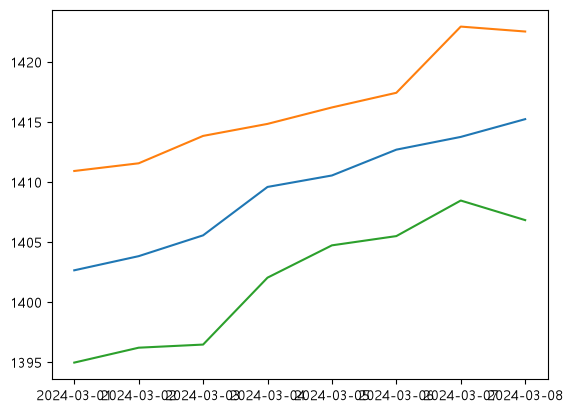

In [153]:
plt.plot(df.temp_core.resample('D').agg(['mean', 'max', 'min']))
plt.show()

In [154]:
list(range(3,10))

[3, 4, 5, 6, 7, 8, 9]

In [155]:
np.arange(3,10)

array([3, 4, 5, 6, 7, 8, 9])

In [157]:
pd.date_range('2026-11-02', periods=7, freq='D')

DatetimeIndex(['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-07', '2026-11-08'],
              dtype='datetime64[us]', freq='D')

In [158]:
pd.date_range('2026-11-02', periods=7, freq='B')

DatetimeIndex(['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10'],
              dtype='datetime64[us]', freq='B')

In [165]:
 #간단한 시계열 데이터 (하루 단위)
dates = pd.date_range('2024-01-01', periods=6, freq='D')
s = pd.Series([10, 20, 30, 40, 50, 60], index=dates)

In [166]:
print(s.asfreq('2D'))

2024-01-01    10
2024-01-03    30
2024-01-05    50
Freq: 2D, dtype: int64


In [168]:
print(s.asfreq('2D').mean())

30.0


In [169]:
len(df['temp_core'])

182

In [174]:
df['temp_core'].isna().sum()

np.int64(0)

In [170]:
len(df['temp_core'].resample('30min'))

383

In [171]:
list(df['temp_core'].resample('30min'))[0]

(Timestamp('2024-03-01 00:00:00'),
 timestamp
 2024-03-01    1399.16
 Name: temp_core, dtype: float64)

In [173]:
list(df['temp_core'].resample('30min'))[1:3]

[(Timestamp('2024-03-01 00:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Timestamp('2024-03-01 01:00:00'),
  timestamp
  2024-03-01 01:00:00    1399.28
  Name: temp_core, dtype: float64)]

In [178]:
up=df['temp_core'].resample('30min').mean()

In [181]:
up

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 00:30:00        NaN
2024-03-01 01:00:00    1399.28
2024-03-01 01:30:00        NaN
2024-03-01 02:00:00    1394.97
                        ...   
2024-03-08 21:00:00    1415.71
2024-03-08 21:30:00        NaN
2024-03-08 22:00:00    1412.78
2024-03-08 22:30:00        NaN
2024-03-08 23:00:00    1419.19
Freq: 30min, Name: temp_core, Length: 383, dtype: float64

In [184]:
up_filled = up.interpolate()

In [185]:
up_filled.isnull().sum()

np.int64(0)

In [186]:
up_filled.head()

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 00:30:00    1399.22
2024-03-01 01:00:00    1399.28
2024-03-01 01:30:00    1397.12
2024-03-01 02:00:00    1394.97
Freq: 30min, Name: temp_core, dtype: float64

In [ ]:
 큰 단위로 전체 잡고 작은 단위로 확대

In [187]:
#실습1

In [2]:
data = "C:\\AI Equipment Failure Prediction\\data\\20_engine01_timestamp_sample.csv"

In [5]:
df = pd.read_csv(data)

In [6]:
df.info() # str 

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  182 non-null    str    
 1   temp_out   182 non-null    float64
 2   temp_core  182 non-null    float64
 3   pressure   180 non-null    float64
 4   vibration  179 non-null    float64
 5   flow       182 non-null    float64
dtypes: float64(5), str(1)
memory usage: 12.0 KB


In [10]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [11]:
df.info() # datetime64[us]

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  182 non-null    datetime64[us]
 1   temp_out   182 non-null    float64       
 2   temp_core  182 non-null    float64       
 3   pressure   180 non-null    float64       
 4   vibration  179 non-null    float64       
 5   flow       182 non-null    float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 8.7 KB


In [198]:
#실습2

In [204]:
df['timestamp'].dt.year.value_counts()

timestamp
2024    182
Name: count, dtype: int64

In [212]:
df['timestamp'].dt.hour[0:3]

0    0
1    1
2    2
Name: timestamp, dtype: int32

In [209]:
df['hour'] = df['timestamp'].dt.hour

In [210]:
df.head()

,timestamp,temp_out,temp_core,pressure,vibration,flow,hour
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.34,0
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.38,1
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.44,2
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.43,3
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.42,4


In [ ]:
df.set_index('timestamp', inplace=True)
df.head()

In [217]:
df.sort_index(inplace=True)

In [224]:
df.head(2)

,temp_out,temp_core,pressure,vibration,flow,hour
timestamp,,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.34,0
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.38,1


In [221]:
df.tail(1)

,temp_out,temp_core,pressure,vibration,flow,hour
timestamp,,,,,,
2024-03-08 23:00:00,642.04,1419.19,546.63,48.09,8.64,23


In [226]:
len(df.loc['2024-03-02'])

20

In [230]:
len(df.loc['2024-03-05' : '2024-03-07'])

70

In [236]:
df_re.head()

timestamp
2024-03-01 00:00:00    1400.08
2024-03-01 06:00:00    1401.98
2024-03-01 12:00:00    1404.08
2024-03-01 18:00:00    1404.25
2024-03-02 00:00:00    1401.59
Freq: 6h, Name: temp_core, dtype: float64

In [243]:
df_mean=df['temp_out'].resample('6h').mean()
df_max=df['temp_out'].resample('6h').max()

In [244]:
df_mean.iloc[0].round(2)

np.float64(641.06)

In [247]:
df_max.iloc[0].round(2)

np.float64(641.18)

In [264]:
for i in ['1h', '6h', '12h']:
    df_mean = len(df['temp_out'].resample(i).mean())
    
    print(f"샘플링 주기 : {i}, Count: {df_mean}")

샘플링 주기 : 1h, Count: 192
샘플링 주기 : 6h, Count: 32
샘플링 주기 : 12h, Count: 16


In [270]:
df_day=df['temp_out'].resample('D').mean()


In [271]:
df.iloc[0]

temp_out      641.17
temp_core    1399.16
pressure      554.91
vibration      47.28
flow            8.34
hour            0.00
Name: 2024-03-01 00:00:00, dtype: float64

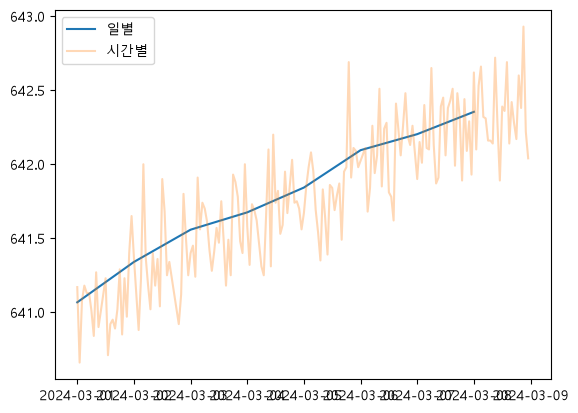

In [272]:
plt.plot(df_day)
plt.plot(df['temp_out'], alpha=0.3)
plt.legend(['일별', '시간별'])
plt.show()


In [273]:
#실습8

In [12]:
df.isna().sum().sum()

np.int64(5)

In [283]:
df_30min = df['flow'].resample('30min')
df_30min

In [14]:
df_30min.head()

NameError: name 'df_30min' is not defined

In [296]:
df_30 = df['flow'].resample('30min').mean()

In [300]:
df_30.isna().sum()

np.int64(201)

In [298]:
df_filled = df_30.interpolate()

In [301]:
df_filled.isnull().sum()    

np.int64(0)

In [13]:
df.columns

Index(['timestamp', 'temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

In [309]:
e1['s_4_diff'] = e1['s_4_저압터빈출구온도'].diff()

In [313]:
e1['s_4_diff'].abs().max().round(2)

np.float64(13.06)

In [314]:
#20_03 

In [315]:
# 실습1

In [21]:
e2 = df[df['unit_nr_엔진번호'] == 2]


In [22]:
e2.sort_index()

,unit_nr_엔진번호,time_cycles_운전주기,setting_1_고도,setting_2_마하수,setting_3_스로틀,s_1_팬입구온도,s_2_저압압축기출구온도,s_3_고압압축기출구온도,s_4_저압터빈출구온도,s_5_팬입구압력,...,s_12_연료흐름압력비,s_13_보정팬회전속도,s_14_보정엔진코어회전속도,s_15_바이패스공기비율,s_16_연료공기비율,s_17_냉각공기관련값,s_18_목표팬회전속도,s_19_보정목표팬회전속도,s_20_고압터빈냉각공기흐름,s_21_저압터빈냉각공기흐름
192,2,1,0.0013,0.0006,100.0,518.67,640.79,1583.91,1400.99,14.62,...,520.52,2388.07,8144.09,8.405,0.03,392,2388,100.0,38.94,23.2552
193,2,2,0.0001,-0.0006,100.0,518.67,641.23,1580.40,1406.14,14.62,...,519.71,2388.07,8134.16,8.366,0.03,391,2388,100.0,39.03,23.2492
194,2,3,-0.0023,0.0003,100.0,518.67,641.10,1582.31,1401.05,14.62,...,521.81,2388.00,8115.97,8.416,0.03,394,2388,100.0,38.81,23.2767
195,2,4,0.0008,-0.0000,100.0,518.67,640.78,1588.53,1409.53,14.62,...,521.14,2388.00,8123.14,8.371,0.03,393,2388,100.0,38.96,23.2157
196,2,5,0.0032,0.0002,100.0,518.67,641.38,1581.18,1394.85,14.62,...,520.36,2388.06,8118.68,8.453,0.03,392,2388,100.0,39.01,23.3252
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474,2,283,0.0004,-0.0003,100.0,518.67,642.51,1597.28,1411.74,14.62,...,514.11,2388.18,8156.16,8.667,0.03,395,2388,100.0,37.95,22.7034
475,2,284,0.0003,-0.0000,100.0,518.67,642.77,1597.95,1423.15,14.62,...,514.19,2388.10,8141.64,8.661,0.03,396,2388,100.0,37.93,22.8475
476,2,285,-0.0002,-0.0001,100.0,518.67,642.50,1604.83,1422.49,14.62,...,513.81,2388.10,8131.01,8.589,0.03,396,2388,100.0,38.07,22.8588
477,2,286,0.0008,-0.0003,100.0,518.67,642.01,1591.69,1412.86,14.62,...,514.03,2388.26,8130.78,8.662,0.03,396,2388,100.0,37.98,22.8460


In [23]:
e2_mean=e2.rolling(window=5).mean().round(2)
e2_mean

,unit_nr_엔진번호,time_cycles_운전주기,setting_1_고도,setting_2_마하수,setting_3_스로틀,s_1_팬입구온도,s_2_저압압축기출구온도,s_3_고압압축기출구온도,s_4_저압터빈출구온도,s_5_팬입구압력,...,s_12_연료흐름압력비,s_13_보정팬회전속도,s_14_보정엔진코어회전속도,s_15_바이패스공기비율,s_16_연료공기비율,s_17_냉각공기관련값,s_18_목표팬회전속도,s_19_보정목표팬회전속도,s_20_고압터빈냉각공기흐름,s_21_저압터빈냉각공기흐름
192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
193,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
194,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
196,2.0,3.0,0.0,0.0,100.0,518.67,641.06,1583.27,1402.51,14.62,...,520.71,2388.04,8127.21,8.40,0.03,392.4,2388.0,100.0,38.95,23.26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
474,2.0,281.0,-0.0,-0.0,100.0,518.67,642.60,1597.82,1415.53,14.62,...,513.92,2388.23,8143.99,8.63,0.03,395.8,2388.0,100.0,38.02,22.78
475,2.0,282.0,-0.0,-0.0,100.0,518.67,642.58,1597.53,1417.23,14.62,...,513.92,2388.21,8143.82,8.63,0.03,395.6,2388.0,100.0,38.00,22.78
476,2.0,283.0,-0.0,-0.0,100.0,518.67,642.53,1599.33,1417.87,14.62,...,513.92,2388.17,8138.75,8.63,0.03,395.8,2388.0,100.0,38.03,22.80
477,2.0,284.0,0.0,-0.0,100.0,518.67,642.50,1598.28,1418.22,14.62,...,513.93,2388.16,8139.69,8.64,0.03,395.8,2388.0,100.0,37.99,22.81


In [346]:
#실습2

In [326]:
e2_rolling = e2['s_11_고압압축기출구정압'].rolling(window=5).std().round(2)
e2_rolling.iloc[4]

np.float64(0.08)

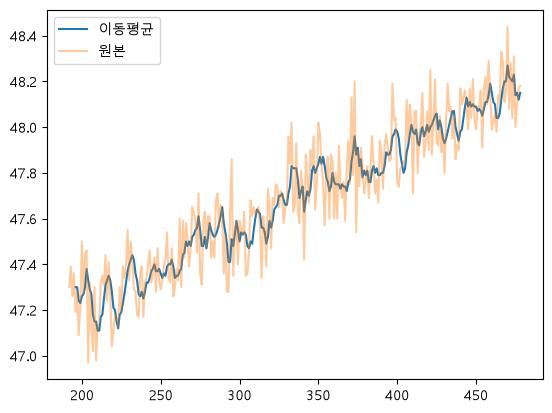

In [348]:
plt.plot(e2_mean['s_11_고압압축기출구정압'])  # 위에서 썻던
plt.plot(e2['s_11_고압압축기출구정압'], alpha=0.4)
plt.legend(['이동평균', '원본'])
plt.show()

In [349]:
#실습3

In [350]:
df.columns.tolist()

['unit_nr_엔진번호',
 'time_cycles_운전주기',
 'setting_1_고도',
 'setting_2_마하수',
 'setting_3_스로틀',
 's_1_팬입구온도',
 's_2_저압압축기출구온도',
 's_3_고압압축기출구온도',
 's_4_저압터빈출구온도',
 's_5_팬입구압력',
 's_6_바이패스통로압력',
 's_7_고압압축기출구압력',
 's_8_팬회전속도',
 's_9_엔진코어회전속도',
 's_10_엔진내부압력비',
 's_11_고압압축기출구정압',
 's_12_연료흐름압력비',
 's_13_보정팬회전속도',
 's_14_보정엔진코어회전속도',
 's_15_바이패스공기비율',
 's_16_연료공기비율',
 's_17_냉각공기관련값',
 's_18_목표팬회전속도',
 's_19_보정목표팬회전속도',
 's_20_고압터빈냉각공기흐름',
 's_21_저압터빈냉각공기흐름']

In [355]:
e2_diff = e2['s_12_연료흐름압력비'].diff()
e2_diff

192     NaN
193   -0.81
194    2.10
195   -0.67
196   -0.78
       ... 
474    0.58
475    0.08
476   -0.38
477    0.22
478   -0.48
Name: s_12_연료흐름압력비, Length: 287, dtype: float64

In [356]:
e2_diff.abs().max().round(2)

np.float64(2.51)

In [362]:
e2_diff.abs().mean().round(4)

np.float64(0.6117)

In [369]:
round(e2['s_12_연료흐름압력비'].pct_change().mean() * 100, 4)

np.float64(-0.0046)

In [370]:
#실습4

In [372]:
df.columns.tolist()

['unit_nr_엔진번호',
 'time_cycles_운전주기',
 'setting_1_고도',
 'setting_2_마하수',
 'setting_3_스로틀',
 's_1_팬입구온도',
 's_2_저압압축기출구온도',
 's_3_고압압축기출구온도',
 's_4_저압터빈출구온도',
 's_5_팬입구압력',
 's_6_바이패스통로압력',
 's_7_고압압축기출구압력',
 's_8_팬회전속도',
 's_9_엔진코어회전속도',
 's_10_엔진내부압력비',
 's_11_고압압축기출구정압',
 's_12_연료흐름압력비',
 's_13_보정팬회전속도',
 's_14_보정엔진코어회전속도',
 's_15_바이패스공기비율',
 's_16_연료공기비율',
 's_17_냉각공기관련값',
 's_18_목표팬회전속도',
 's_19_보정목표팬회전속도',
 's_20_고압터빈냉각공기흐름',
 's_21_저압터빈냉각공기흐름']

In [385]:
sensors = df.std().round(2).sort_values() > 0.01

for i in sensors[sensors].index:
    print(i, df[i].std().round(2))

setting_2_마하수       False
setting_1_고도        False
s_1_팬입구온도           False
setting_3_스로틀       False
s_6_바이패스통로압력        False
s_10_엔진내부압력비        False
s_5_팬입구압력           False
s_18_목표팬회전속도        False
s_19_보정목표팬회전속도      False
s_16_연료공기비율         False
s_13_보정팬회전속도         True
s_15_바이패스공기비율        True
s_8_팬회전속도            True
s_21_저압터빈냉각공기흐름      True
s_20_고압터빈냉각공기흐름      True
s_11_고압압축기출구정압       True
s_2_저압압축기출구온도        True
unit_nr_엔진번호         True
s_17_냉각공기관련값         True
s_12_연료흐름압력비         True
s_7_고압압축기출구압력        True
s_3_고압압축기출구온도        True
s_4_저압터빈출구온도         True
s_9_엔진코어회전속도         True
s_14_보정엔진코어회전속도      True
time_cycles_운전주기     True
dtype: bool

In [376]:
sensors = [c for c in cand if df[c].std() > 0.01]
#전체상관분석
df.corr().round(2)

,unit_nr_엔진번호,time_cycles_운전주기,setting_1_고도,setting_2_마하수,setting_3_스로틀,s_1_팬입구온도,s_2_저압압축기출구온도,s_3_고압압축기출구온도,s_4_저압터빈출구온도,s_5_팬입구압력,...,s_12_연료흐름압력비,s_13_보정팬회전속도,s_14_보정엔진코어회전속도,s_15_바이패스공기비율,s_16_연료공기비율,s_17_냉각공기관련값,s_18_목표팬회전속도,s_19_보정목표팬회전속도,s_20_고압터빈냉각공기흐름,s_21_저압터빈냉각공기흐름
unit_nr_엔진번호,1.00,0.05,-0.01,0.06,NaN,NaN,0.01,-0.03,0.03,NaN,...,-0.00,0.00,-0.02,0.00,NaN,-0.00,NaN,NaN,-0.00,-0.01
time_cycles_운전주기,0.05,1.00,-0.05,0.01,NaN,NaN,0.82,0.72,0.74,NaN,...,-0.90,0.70,0.31,0.85,NaN,0.74,NaN,NaN,-0.88,-0.88
setting_1_고도,-0.01,-0.05,1.00,-0.04,NaN,NaN,0.00,-0.00,-0.03,NaN,...,0.02,0.00,-0.02,-0.02,NaN,0.02,NaN,NaN,0.03,0.02
setting_2_마하수,0.06,0.01,-0.04,1.00,NaN,NaN,0.01,-0.03,-0.04,NaN,...,0.01,0.01,-0.03,-0.02,NaN,0.00,NaN,NaN,0.00,0.02
setting_3_스로틀,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
s_1_팬입구온도,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
s_2_저압압축기출구온도,0.01,0.82,0.00,0.01,NaN,NaN,1.00,0.66,0.69,NaN,...,-0.84,0.67,0.30,0.81,NaN,0.70,NaN,NaN,-0.84,-0.83
s_3_고압압축기출구온도,-0.03,0.72,-0.00,-0.03,NaN,NaN,0.66,1.00,0.62,NaN,...,-0.75,0.57,0.26,0.71,NaN,0.62,NaN,NaN,-0.72,-0.73
s_4_저압터빈출구온도,0.03,0.74,-0.03,-0.04,NaN,NaN,0.69,0.62,1.00,NaN,...,-0.76,0.60,0.25,0.73,NaN,0.64,NaN,NaN,-0.76,-0.75
s_5_팬입구압력,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
df.corr().round(2)

,unit_nr_엔진번호,time_cycles_운전주기,setting_1_고도,setting_2_마하수,setting_3_스로틀,s_1_팬입구온도,s_2_저압압축기출구온도,s_3_고압압축기출구온도,s_4_저압터빈출구온도,s_5_팬입구압력,...,s_12_연료흐름압력비,s_13_보정팬회전속도,s_14_보정엔진코어회전속도,s_15_바이패스공기비율,s_16_연료공기비율,s_17_냉각공기관련값,s_18_목표팬회전속도,s_19_보정목표팬회전속도,s_20_고압터빈냉각공기흐름,s_21_저압터빈냉각공기흐름
unit_nr_엔진번호,1.00,0.05,-0.01,0.06,NaN,NaN,0.01,-0.03,0.03,NaN,...,-0.00,0.00,-0.02,0.00,NaN,-0.00,NaN,NaN,-0.00,-0.01
time_cycles_운전주기,0.05,1.00,-0.05,0.01,NaN,NaN,0.82,0.72,0.74,NaN,...,-0.90,0.70,0.31,0.85,NaN,0.74,NaN,NaN,-0.88,-0.88
setting_1_고도,-0.01,-0.05,1.00,-0.04,NaN,NaN,0.00,-0.00,-0.03,NaN,...,0.02,0.00,-0.02,-0.02,NaN,0.02,NaN,NaN,0.03,0.02
setting_2_마하수,0.06,0.01,-0.04,1.00,NaN,NaN,0.01,-0.03,-0.04,NaN,...,0.01,0.01,-0.03,-0.02,NaN,0.00,NaN,NaN,0.00,0.02
setting_3_스로틀,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
s_1_팬입구온도,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
s_2_저압압축기출구온도,0.01,0.82,0.00,0.01,NaN,NaN,1.00,0.66,0.69,NaN,...,-0.84,0.67,0.30,0.81,NaN,0.70,NaN,NaN,-0.84,-0.83
s_3_고압압축기출구온도,-0.03,0.72,-0.00,-0.03,NaN,NaN,0.66,1.00,0.62,NaN,...,-0.75,0.57,0.26,0.71,NaN,0.62,NaN,NaN,-0.72,-0.73
s_4_저압터빈출구온도,0.03,0.74,-0.03,-0.04,NaN,NaN,0.69,0.62,1.00,NaN,...,-0.76,0.60,0.25,0.73,NaN,0.64,NaN,NaN,-0.76,-0.75
s_5_팬입구압력,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [45]:
df.columns.to_list()

['unit_nr',
 'time_cycles',
 'setting_1',
 'setting_2',
 'setting_3',
 's_1',
 's_2',
 's_3',
 's_4',
 's_5',
 's_6',
 's_7',
 's_8',
 's_9',
 's_10',
 's_11',
 's_12',
 's_13',
 's_14',
 's_15',
 's_16',
 's_17',
 's_18',
 's_19',
 's_20',
 's_21']

In [30]:
df['s_4_저압터빈출구온도'].corr(df['s_7_고압압축기출구압력'])

np.float64(-0.7669596882740883)

In [ ]:
cand = [f's_{i}' for i in range(1, 22)]
sensors = [c for c in cand if df[c].std() > 0.01]
corr = df[sensors].corr()
print(corr['s_11'].drop('s_11').sort_values(ascending=False).head(3).round(3))
print(corr['s_11'].sort_values().head(3).round(3))

In [41]:
cand = [f's_{i}' for i in range(1, 22)]
sensors = [c for c in cand if df[c].std() > 0.01]

In [42]:
corr = df[sensors].corr()
print(corr['s_11'].drop('s_11').sort_values(ascending=False).head(3).round(3))
print(corr['s_11'].sort_values().head(3).round(3))

s_15    0.847
s_2     0.804
s_8     0.769
Name: s_11, dtype: float64
s_7    -0.886
s_12   -0.885
s_20   -0.874
Name: s_11, dtype: float64


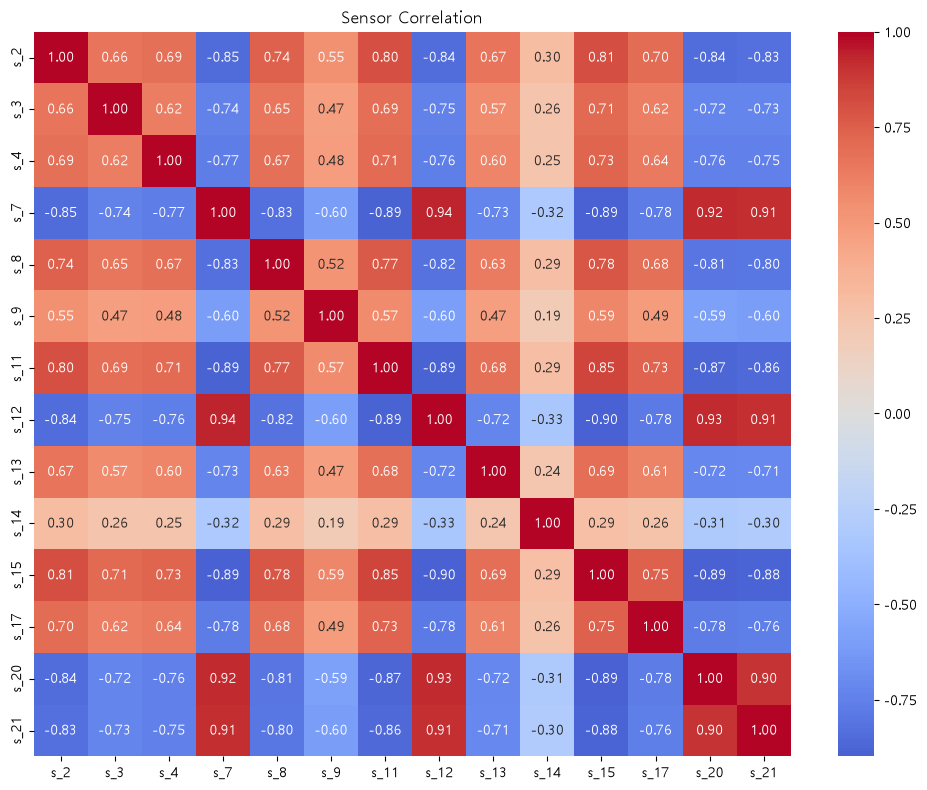

In [43]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Sensor Correlation'); plt.tight_layout()
plt.show()

In [57]:
for col in ['s_11', 's_12', 's_3']:
    ma = e2[col].rolling(5).mean()
    tr = '상승 ' if ma.dropna().iloc[-1] > ma.dropna().iloc[0] else '하강 '
    s = e2[col].rolling(5).std(); h = len(e2) // 2
    vol = '증가 ' if s.iloc[h:].mean() > s.iloc[:h].mean() else '감소 '
    print(col, '추세 ', tr, '변동성 ', vol)

s_11 추세  상승  변동성  증가 
s_12 추세  하강  변동성  감소 
s_3 추세  상승  변동성  증가 
